# Cell-Cycle Scoring and Regression

### Aim:
find which pahse of the cell cycle each cell is in, then remove that effect so cells group by cell type rather than by whether they are diving. 

### Why is it important:
a cell's genes change a lot while it divides. Twl cells of the same type, one dividing and one resting can look different enough to be in different clusters. 

### Cell cycle overview:
G1 (resting/growing) -> S (copying DNA) -> G2/M (getting ready to divide, then dividing)

Different genes switched on during different phases which can be used as markers

### Data:
mouse blood progenitor cells (Nestorowa et al., 2016)

### Workflow:
1. Load the data and teh cell-cycle gene list
2. Normalise and log-transform
3. Score each cell for S and G2M phase (most distintive genes that switched on during these phases)
4. PCA on cell-cycle gnees only: cells separate by phase
5. Remove (regress out) the cell-cycle effect
6. PCA again: cells no longer separate by phase

In [2]:
from __future__ import annotations
import zipfile
import pooch
import scanpy as sc
sc.logging.print_header()

/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/IPython/core/formatters.py:1035: RuntimeWarning: Failed to import dependencies for application/vnd.jupyter.widget-view+json representation. (ModuleNotFoundError: No module named 'ipywidgets')
  return method(include=include, exclude=exclude)


Package,Version
pooch,1.9.0 (v1.9.0)
scanpy,1.12.4
Component,Info
Python,"3.12.8 | packaged by Anaconda, Inc. | (main, Dec 11 2024, 10:37:40) [Clang 14.0.6 ]"
OS,macOS-15.3.1-arm64-arm-64bit
CPU,"8/8 logical CPU cores, arm"
GPU,No GPU found
Updated,2026-10-21 23:14
Dependency,Version
numcodecs,0.17.0


In [6]:
p_zip = pooch.retrieve(
    "https://www.dropbox.com/s/3dby3bjsaf5arrw/cell_cycle_vignette_files.zip?dl=1",
    known_hash="sha256:6557fe2a2761d1550d41edf61b26c6d5ec9b42b4933d56c3161164a595f145ab",
    path="cell-cycle-data",
)

In [ ]:
# read the data and cell cycle genes from the zip file
with zipfile.ZipFile(p_zip, "r") as f_zip:
    f_csv = zipfile.Path(f_zip, "nestorawa_forcellcycle_expressionMatrix.txt").open()
    adata = sc.read_csv(f_csv, delimiter="\t").T
    cell_cycle_genes = zipfile.Path(f_zip, "regev_lab_cell_cycle_genes.txt").read_text().splitlines()

In [ ]:
# Splitting S and G2M phase genes
# the first 43 genes are S phase genes, and the remaining 54 genes are G2M phase genes.
s_genes = [x for x in cell_cycle_genes[:43] if x in adata.var_names]
g2m_genes = [x for x in cell_cycle_genes[43:] if x in adata.var_names]
cell_cycle_genes = [*s_genes, *g2m_genes]

In [ ]:
# checking the number of genes in each phase as the list for human and dataset is mouse
len(s_genes), len(g2m_genes)

(41, 54)

In [ ]:
# filter and normalize the data
sc.pp.filter_cells(adata, min_genes=200) # remove cells with less than 200 genes
sc.pp.filter_genes(adata, min_cells=3) # remove genes found less than 3 cells
sc.pp.normalize_total(adata, target_sum=1e4) # scale each cell count to total 10,000
sc.pp.log1p(adata) # log-transform the data

In [ ]:
# score each cell
sc.tl.score_genes_cell_cycle(adata, s_genes=s_genes, g2m_genes=g2m_genes)

# average expression of the S genes in that cell
# average expression of control genes that randomly chosen genes with similar overall expression levels
# the score = average expression of the S genes - average expression of control genes
# positive means S genes are higher than by chance
# arouund zero or negative means they are not
# repeat this scoring for G2M genes as well 
# if both S score and G2M score are negative, the cell is in G1 phase
# if S score is higher than G2M score, the cell is in S phase
# if G2M score is higher than S score, the cell is in G2M phase

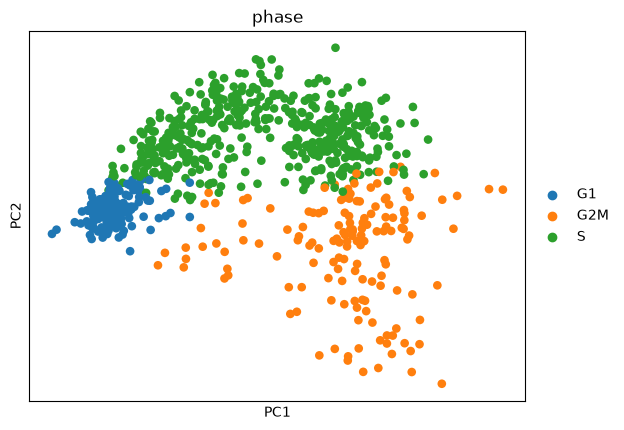

In [ ]:
# PCA on cell-cycle genes only
adata_cc_genes = adata[:, cell_cycle_genes].copy()
sc.tl.pca(adata_cc_genes)
sc.pl.pca(adata_cc_genes, color="phase")

/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/scanpy/preprocessing/_simple.py:660: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff
/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/scanpy/preprocessing/_simple.py:660: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff


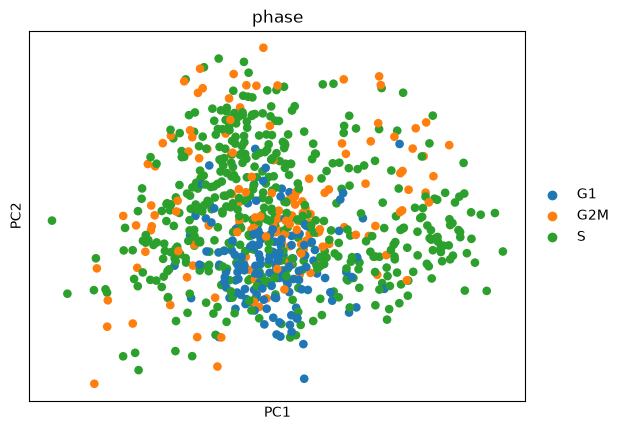

In [ ]:
# Remove the cell-cycle effect by regressing out the S and G2M scores
adata.layers["log_norm"] = adata.X.copy()
sc.pp.regress_out(adata, ["S_score", "G2M_score"])
adata_cc_genes = adata[:, cell_cycle_genes].copy()
sc.tl.pca(adata_cc_genes)
sc.pl.pca(adata_cc_genes, color="phase")

# the phase are well mixed after regressing out the cell-cycle effect, which means the cell-cycle effect is removed